# CVaR Portfolio Optimization
## Theory, Implementation, and Duality Analysis

**References**
- R. T. Rockafellar, S. Uryasev (2000). *Optimization of Conditional Value-at-Risk.* Journal of Risk 2(3), 21–41.
- R. T. Rockafellar, S. Uryasev (2002). *Conditional value-at-risk for general loss distributions.* Journal of Banking & Finance 26(7), 1443–1471.
- C. Acerbi, D. Tasche (2002). *On the coherence of expected shortfall.* Journal of Banking & Finance 26(7), 1487–1503.
- P. Artzner, F. Delbaen, J.-M. Eber, D. Heath (1999). *Coherent measures of risk.* Mathematical Finance 9(3), 203–228.

---

### 1. Motivation

The first technique usually taught in portfolio optimization is Markowitz *minimum variance*. Variance is symmetric: a portfolio that outperforms is penalised just as much as one that underperforms. On the plus side, the problem is a convex QP with an essentially closed-form solution.

The next step is usually *Value at Risk* (VaR), which is used in practice (Basel II) and focuses on the loss tail. Mathematically it is unpleasant: as a function of the portfolio weights it is in general neither convex nor subadditive. Merging two portfolios can therefore *increase* VaR, so VaR does not reliably reward diversification, and optimising it is a non-convex problem.

*Conditional Value at Risk* (CVaR, also *Expected Shortfall*) fixes both issues.

### 2. Definition

For a loss $L$ and confidence level $\alpha \in (0,1)$ (typically $0.95$):

$$
\operatorname{VaR}_\alpha(L) = \min\{\ell : P(L \le \ell) \ge \alpha\}, \qquad
\operatorname{CVaR}_\alpha(L) = \min_{\eta \in \mathbb{R}} \; \eta + \frac{1}{1-\alpha}\, \mathbb{E}\big[(L-\eta)_+\big].
$$

The popular formula $\mathbb{E}[L \mid L \ge \operatorname{VaR}_\alpha(L)]$ agrees with this **only if $L$ has no atom at the VaR**. Empirical distributions consist of atoms only, so we use the Rockafellar–Uryasev / Acerbi–Tasche definition above. For $T$ equally likely scenarios, with $k=(1-\alpha)T$, $m=\lfloor k \rfloor$ and losses sorted in decreasing order $L_{(1)} \ge L_{(2)} \ge \dots$:

$$
\operatorname{CVaR}_\alpha = \frac{1}{k}\Big(\sum_{i=1}^{m} L_{(i)} + (k-m)\, L_{(m+1)}\Big).
$$

The minimisers $\eta^*$ form a closed interval whose left endpoint is $\operatorname{VaR}_\alpha$. A solver returns *some* element of this interval, so $\eta^*$ need not equal the VaR.

CVaR is a *coherent* risk measure (Artzner et al.): it is monotone, translation-equivariant ($\rho(L+m)=\rho(L)+m$), positively homogeneous and subadditive. Positive homogeneity together with subadditivity gives *convexity*. Subadditivity means $\rho(L_1+L_2)\le\rho(L_1)+\rho(L_2)$: merging positions never creates risk beyond the sum of the parts. It does *not* mean that every additional asset lowers risk.

**Losses use simple returns.** With simple returns $R_t$ the portfolio return is $R_t^\top w$, which is linear in $w$. Log-returns do not aggregate linearly across assets, so $-r_t^\top w$ built from log-returns is not the portfolio loss.

### 3. Linear Program

Replacing $(\cdot)_+$ by auxiliary variables $z_t$ yields the LP (Rockafellar & Uryasev, 2000):

$$
\min_{w \in W,\ \eta,\ z \ge 0} \; \eta + \frac{1}{k}\sum_{t=1}^T z_t
\quad \text{s.t.} \quad z_t + \eta + R_t^\top w \ge 0 \quad (\text{dual } q_t \ge 0),
$$

where $W = \{w : \mathbf 1^\top w = 1,\ w \ge 0\}$ (optionally with box or return-target constraints).

### 4. Duality: the Worst-Case Measure

Let $c = 1/k$. CVaR is the **support function of the risk envelope**

$$
\mathcal Q = \Big\{ q \in \mathbb R^T : 0 \le q_t \le c,\ \textstyle\sum_t q_t = 1 \Big\}, \qquad
\operatorname{CVaR}_\alpha(L) = \max_{q \in \mathcal Q} \langle q, L \rangle ,
$$

so its Fenchel conjugate is the indicator function $\delta_{\mathcal Q}$. For $L(w) = -Rw$ this gives a bilinear saddle-point problem on compact convex sets, so minimax holds:

$$
\min_{w\in W}\max_{q\in\mathcal Q} \langle q,-Rw\rangle \;=\; \max_{q\in\mathcal Q} g(q),\qquad
g(q) = \min_{w\in W} -(R^\top q)^\top w \;\overset{W=\Delta}{=}\; \min_i \mathbb E_q[-r_i].
$$

$g$ is exactly the Lagrange dual function of the LP once $\eta$ and $z$ are eliminated, and the LP multipliers $q^*$ maximise it. Read economically, the dual chooses the probability reweighting of history, with likelihood ratio at most $1/(1-\alpha)$, under which the *best* asset looks as bad as possible.

**Structure of $q^*$.** The extreme points of $\mathcal Q$ put mass $c$ on $\lfloor k\rfloor$ scenarios and the rest on one further scenario. After optimising over $w$, however, several scenarios typically lie **exactly at $\eta^*$**: the optimiser pushes them onto the kink of $(\cdot)_+$. In that case $q^*$ is not unique and can spread *fractional* mass over these ties. "Uniform on the worst $\lceil(1-\alpha)T\rceil$ days" is only the special case without ties.

**KKT in $w$.** With $a_i = \mathbb E_{Q^*}[-r_i]$, stationarity and complementary slackness for $W=\Delta$ give

$$
a_i = \lambda^* \ \text{ if } w_i^*>0, \qquad a_i \ge \lambda^* \ \text{ if } w_i^*=0, \qquad \lambda^* = \sum_i w_i^* a_i = \operatorname{CVaR}^*.
$$

Every held asset has the same expected loss under the worst-case measure, and this common value is the optimal CVaR. The terms $w_i^* a_i$ form the Euler decomposition of CVaR (positive homogeneity) and sum exactly to $\operatorname{CVaR}^*$.

In [36]:
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Install once from the repo root:  pip install -e .
from cvar_portfolio import DualAnalysis, empirical_cvar, optimize_mean_variance, optimize_min_cvar
from cvar_portfolio.data import fetch_data
from cvar_portfolio.metrics import out_of_sample_evaluation
from cvar_portfolio.robustness import (
    alpha_sensitivity, bootstrap_weights, cvar_difference_ci, rolling_backtest,
)
from cvar_portfolio import plots

ALPHA = 0.95
pd.set_option("display.float_format", "{:.6g}".format)
print("Done.")

Done.


## Step 1: Load Data

Prices are downloaded once from Yahoo Finance and then cached in `data_cache/`, which makes later runs reproducible and possible offline.

*Caveat:* the universe consists of today's large caps (survivorship / look-ahead bias). That is fine for illustrating the mathematics, but the backtest results should not be read as evidence about real-world performance.

In [37]:
data = fetch_data(start="2010-01-01", end="2025-12-31", train_end="2021-12-31")

print(f"Assets : {data.tickers}")
print(f"Train  : {data.train_dates[0].date()} - {data.train_dates[-1].date()} ({len(data.train_dates)} days)")
print(f"Test   : {data.test_dates[0].date()} - {data.test_dates[-1].date()} ({len(data.test_dates)} days)")

summary = pd.DataFrame({
    "Ann. Return": data.train_returns.mean(axis=0) * 252,
    "Ann. Vol": data.train_returns.std(axis=0, ddof=1) * np.sqrt(252),
}, index=data.tickers)
summary.style.format("{:.2%}")

Assets : ['AAPL', 'AMZN', 'BAC', 'CVX', 'GOOGL', 'GS', 'JNJ', 'JPM', 'KO', 'MSFT', 'PFE', 'PG', 'WMT', 'XOM']
Train  : 2010-01-05 - 2021-12-31 (3020 days)
Test   : 2022-01-03 - 2025-12-30 (1002 days)


,Ann. Return,Ann. Vol
AAPL,31.48%,28.05%
AMZN,31.68%,31.17%
BAC,16.08%,34.94%
CVX,10.97%,27.03%
GOOGL,21.87%,25.82%
GS,12.36%,29.10%
JNJ,12.48%,16.79%
JPM,17.45%,28.42%
KO,10.72%,17.36%
MSFT,25.21%,25.06%


## Step 2: Solve the CVaR-LP and the Minimum-Variance Benchmark

In [38]:
cvar_result = optimize_min_cvar(data.train_returns, alpha=ALPHA)
mv_result   = optimize_mean_variance(data.train_returns, alpha=ALPHA)
results = {"Min-CVaR": cvar_result, "Min-Variance": mv_result}

weights = pd.DataFrame({k: v.weights for k, v in results.items()}, index=data.tickers)
display(weights.clip(lower=0).round(4).sort_values("Min-CVaR", ascending=False))

pd.DataFrame({
    k: {"CVaR (daily)": v.cvar, "VaR (daily)": v.var, "eta* (LP)": v.eta,
        "E[r] (daily)": v.expected_return, "Vol (daily)": v.volatility, "Sharpe (ann.)": v.sharpe}
    for k, v in results.items()
})

,Min-CVaR,Min-Variance
PG,0.2709,0.19
WMT,0.2563,0.2219
JNJ,0.2035,0.2238
KO,0.1354,0.2097
PFE,0.0846,0.0742
AMZN,0.0491,0.0409
AAPL,0,0.0049
BAC,0,0
CVX,0,0
GOOGL,0,0.0078


,Min-CVaR,Min-Variance
CVaR (daily),0.0196219,0.0197854
VaR (daily),0.0121511,0.0121555
eta* (LP),0.0121511,NaN
E[r] (daily),0.000534947,0.000521023
Vol (daily),0.00858036,0.00852114
Sharpe (ann.),0.989705,0.970642


As expected, Min-CVaR has the lower in-sample CVaR and Min-Variance the lower volatility. $\eta^*$ lies in the argmin interval $[\operatorname{VaR}_\alpha, \cdot\,]$ and need not equal the VaR.

## Step 3: The Dual Measure $Q^*$

In [39]:
dual = DualAnalysis(result=cvar_result, dates=data.train_dates,
                    returns=data.train_returns, tickers=data.tickers)
pd.Series(dual.scenario_concentration(), name="value").to_frame()

,value
alpha,0.95
T,3020
k = (1-alpha)T,151
c = 1/k,0.00662252
theory: full atoms floor(k),151
active scenarios (q>0),155
full atoms (q=c),149
fractional atoms (0<q<c),6
mass on fractional atoms,0.013245
scenarios tied at eta*,6


,date,q,q_over_c,portfolio_loss,atom
0,2020-03-12,0.00662252,1,0.0794404,full
1,2020-03-20,0.00662252,1,0.0600274,full
2,2020-03-16,0.00662252,1,0.0587248,full
3,2020-03-11,0.00662252,1,0.0571714,full
4,2020-03-19,0.00662252,1,0.0454671,full
5,2018-02-05,0.00662252,1,0.0429961,full
6,2020-02-27,0.00662252,1,0.0392457,full
7,2018-02-20,0.00662252,1,0.0366175,full
8,2015-08-24,0.00662252,1,0.0365839,full
9,2011-08-10,0.00662252,1,0.0354222,full


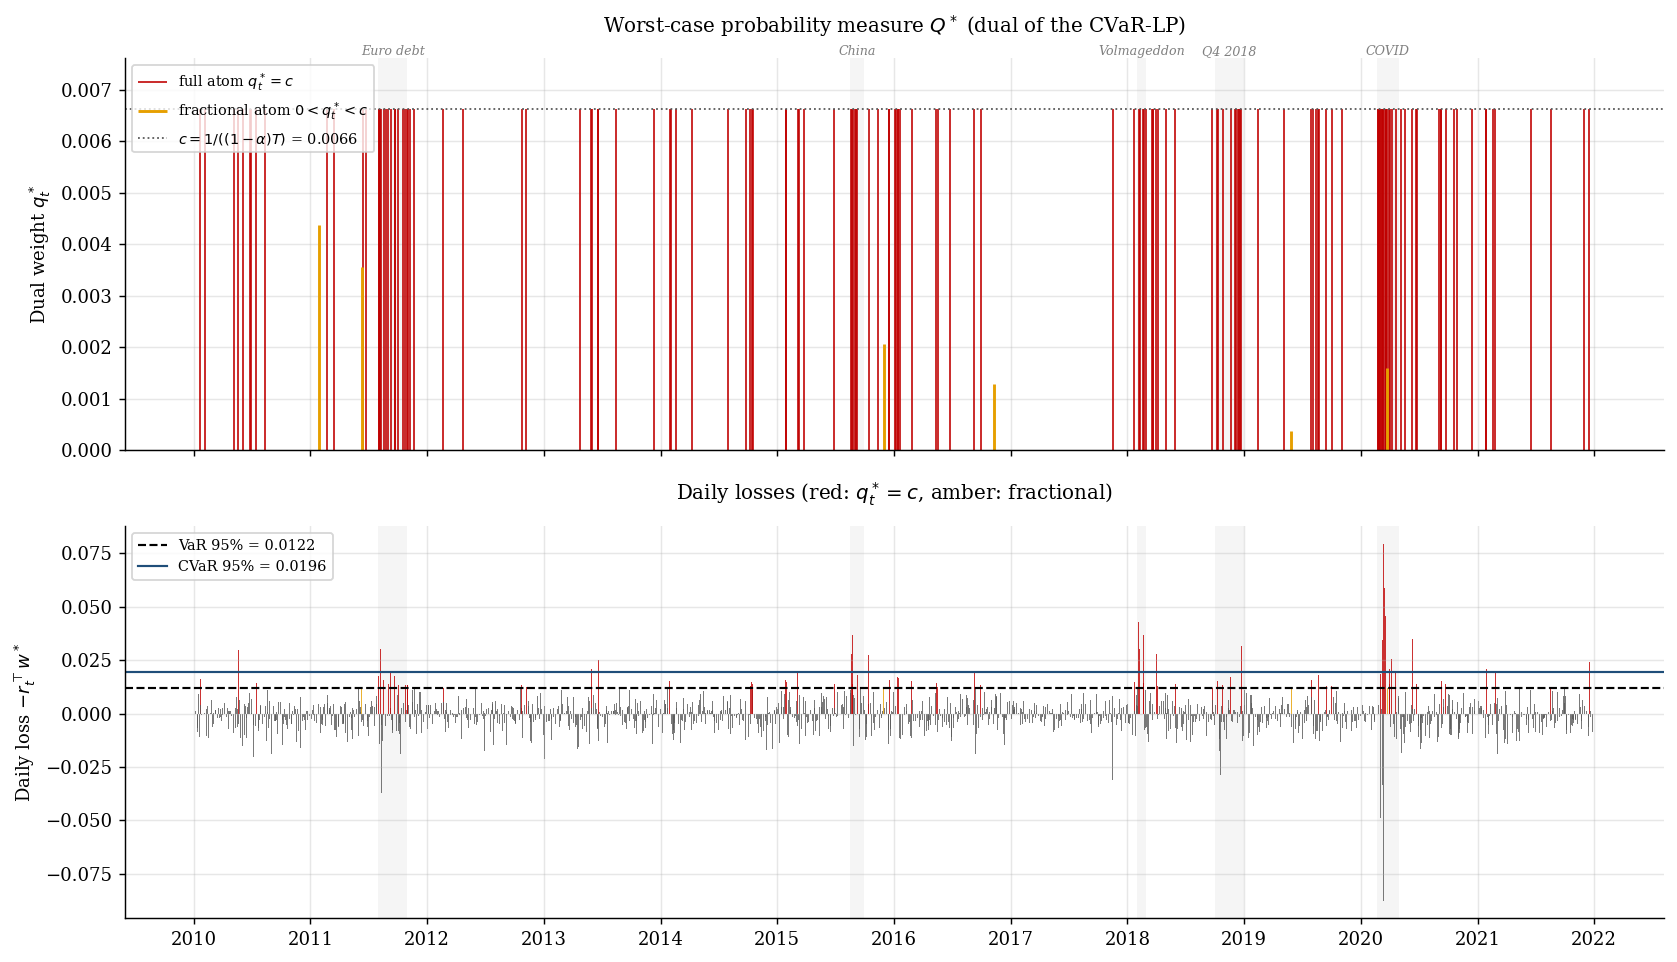

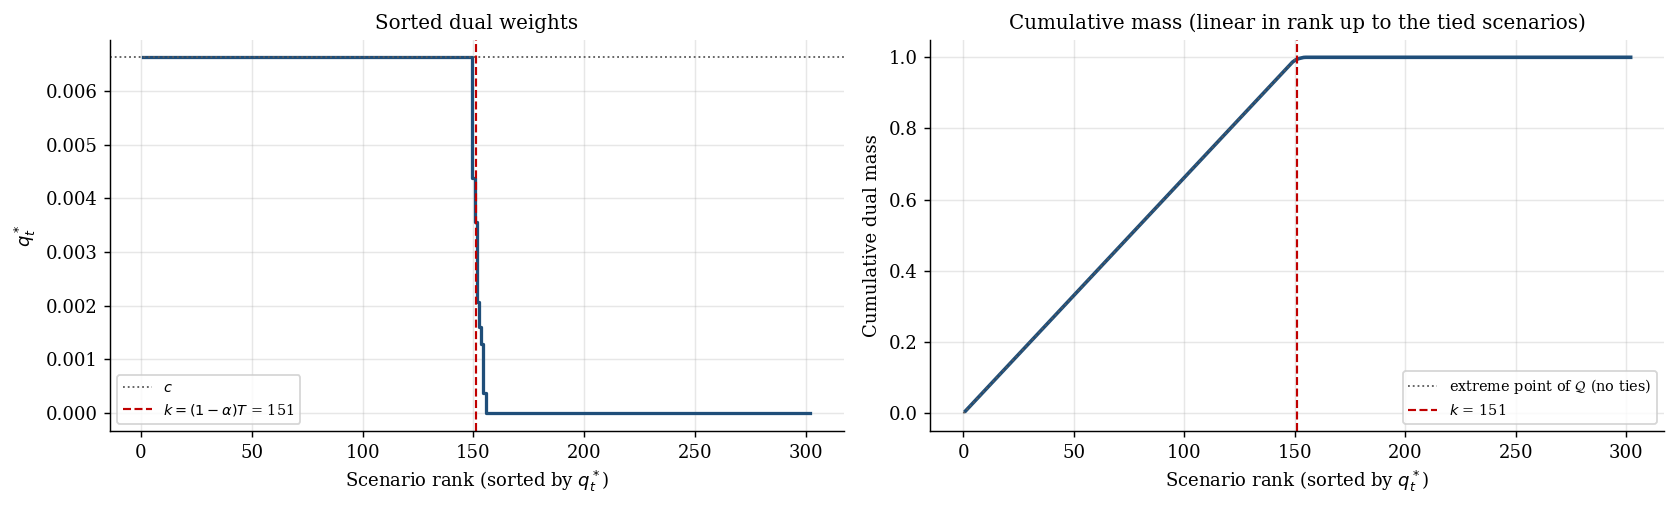

In [40]:
display(dual.tail_scenarios.head(15))
fig = plots.plot_dual_weights(dual, save_path="results/dual_weights.png"); plt.show()
fig = plots.plot_dual_mass(dual, save_path="results/dual_mass.png"); plt.show()

The dual mass sits on genuine stress episodes in the training window: the 2011 euro crisis, August 2015, February 2018, Q4 2018 and, above all, March 2020. (The 2008 crisis lies *before* the training window.) The cumulative mass grows linearly with slope $c$ and reaches 1 in the region of the tied scenarios, not exactly at a single index.

## Step 4: KKT Conditions and Euler Risk Contributions

lambda* = 0.0196219   CVaR* = 0.0196219


,weight,E_Q[-r_i],status,E_Q[-r_i] - lambda,kkt_ok
AMZN,0.0491284,0.0196219,interior,3.71102e-12,True
PFE,0.08463,0.0196219,interior,4.97399e-12,True
PG,0.270947,0.0196219,interior,5.18899e-12,True
JNJ,0.203544,0.0196219,interior,5.21638e-12,True
WMT,0.256316,0.0196219,interior,5.22133e-12,True
KO,0.135434,0.0196219,interior,5.38162e-12,True
AAPL,7.0857e-12,0.0204946,at 0,0.000872733,True
GOOGL,6.97031e-12,0.0205567,at 0,0.000934844,True
XOM,5.91095e-12,0.0206672,at 0,0.00104538,True
CVX,2.39969e-12,0.0219655,at 0,0.00234366,True


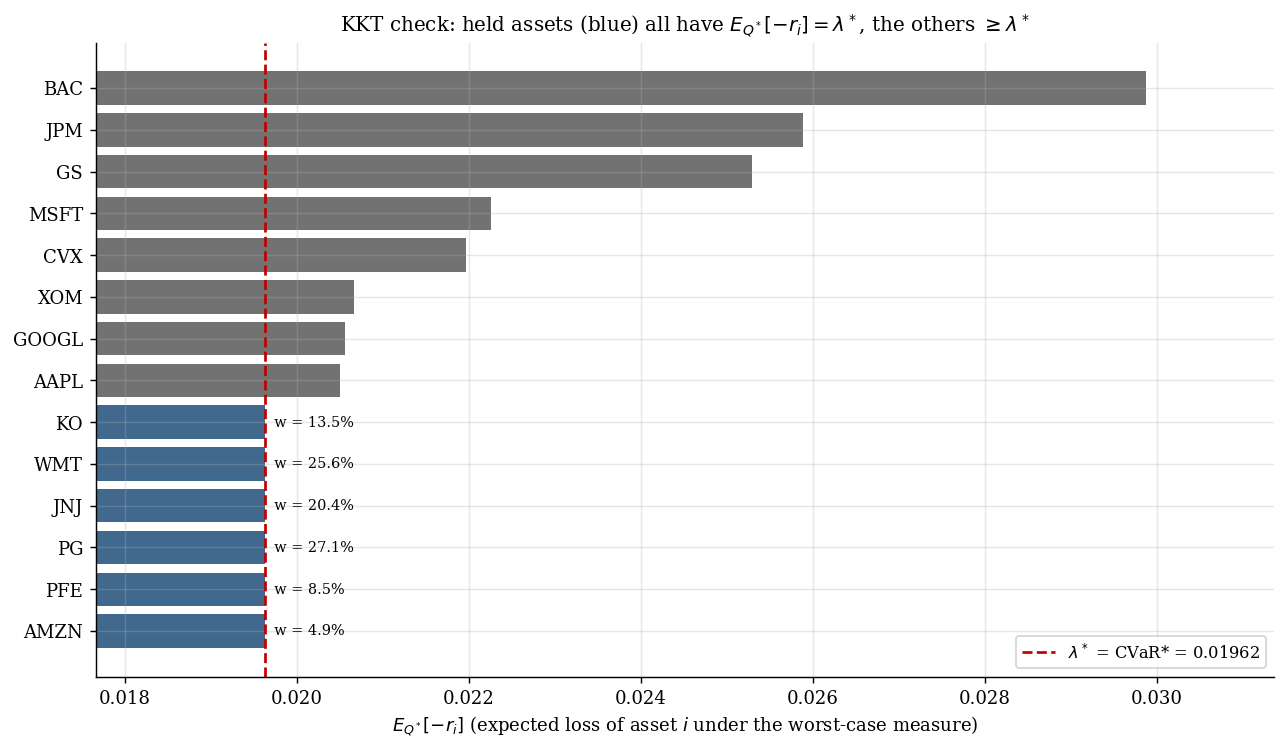

In [41]:
kkt = dual.kkt_table()
print(f"lambda* = {kkt.attrs['lambda']:.6g}   CVaR* = {cvar_result.cvar:.6g}")
display(kkt)
fig = plots.plot_kkt(dual, save_path="results/kkt.png"); plt.show()

,weight,E_Q[-r_i],contribution,share
PG,0.270947,0.0196219,0.00531649,0.270947
WMT,0.256316,0.0196219,0.0050294,0.256316
JNJ,0.203544,0.0196219,0.00399391,0.203544
KO,0.135434,0.0196219,0.00265747,0.135434
PFE,0.08463,0.0196219,0.0016606,0.08463
AMZN,0.0491284,0.0196219,0.00096399,0.0491284
AAPL,7.0857e-12,0.0204946,1.45218e-13,7.40085e-12
GOOGL,6.97031e-12,0.0205567,1.43287e-13,7.3024e-12
XOM,5.91095e-12,0.0206672,1.22163e-13,6.22586e-12
CVX,2.39969e-12,0.0219655,5.27105e-14,2.68631e-12


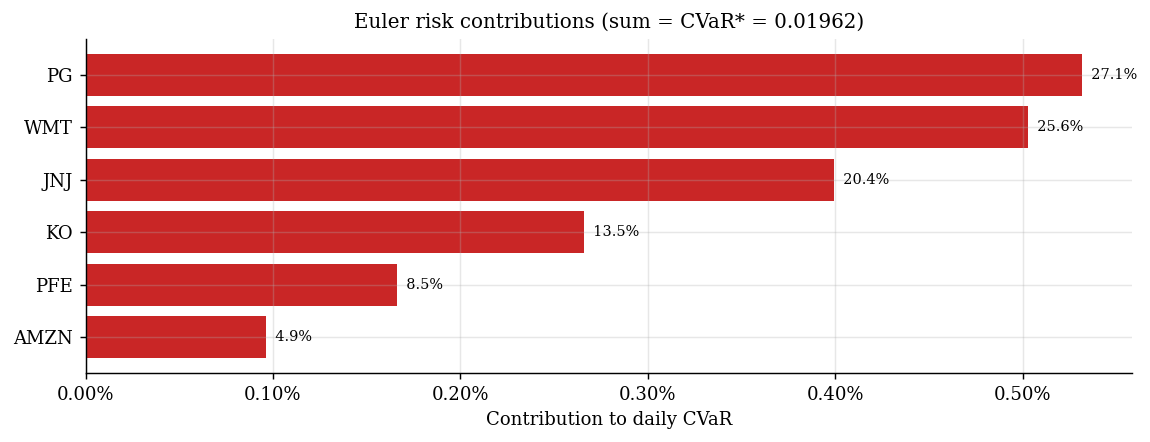

In [42]:
display(dual.risk_contributions())
fig = plots.plot_risk_contributions(dual, save_path="results/risk_contributions.png"); plt.show()

All held assets have *identical* expected loss under $Q^*$, equal to $\operatorname{CVaR}^*$. Assets with weight zero are strictly worse under $Q^*$. This gives a certificate of optimality that can be read off directly from the dual. The Euler contributions add up exactly to $\operatorname{CVaR}^*$. Under the worst-case measure, marginal risk is equalised across the held assets, so the contributions are proportional to the weights.

## Step 5: Compare Portfolios

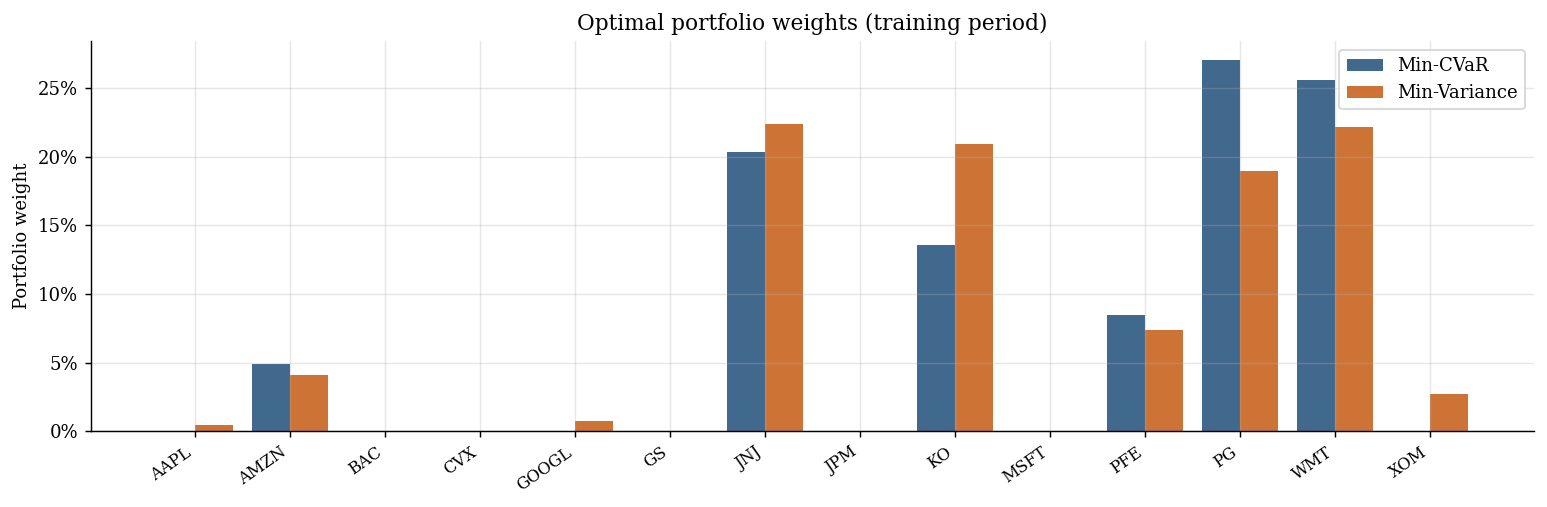

In [43]:
fig = plots.plot_weights(results, data.tickers, save_path="results/portfolios.png"); plt.show()

## Step 6: Out-of-Sample Evaluation

The in-sample weights are held fixed (daily rebalanced) over the test period. Risk figures are **daily** and deliberately not annualised: the $\sqrt{252}$ rule is justified only for standard deviations of i.i.d. returns, not for tail measures of fat-tailed, dependent returns.

Portfolio,Min-CVaR,Min-Variance
ann_return,0.0928657,0.101101
cagr,0.087488,0.0971667
ann_vol,0.134031,0.129256
sharpe,0.692869,0.782174
sortino,1.00411,1.13811
max_drawdown,-0.175816,-0.160715
calmar,0.497611,0.604589
var_95%_daily,0.0124798,0.0118444
cvar_95%_daily,0.0180835,0.0173435
cvar_to_var,1.44902,1.46428


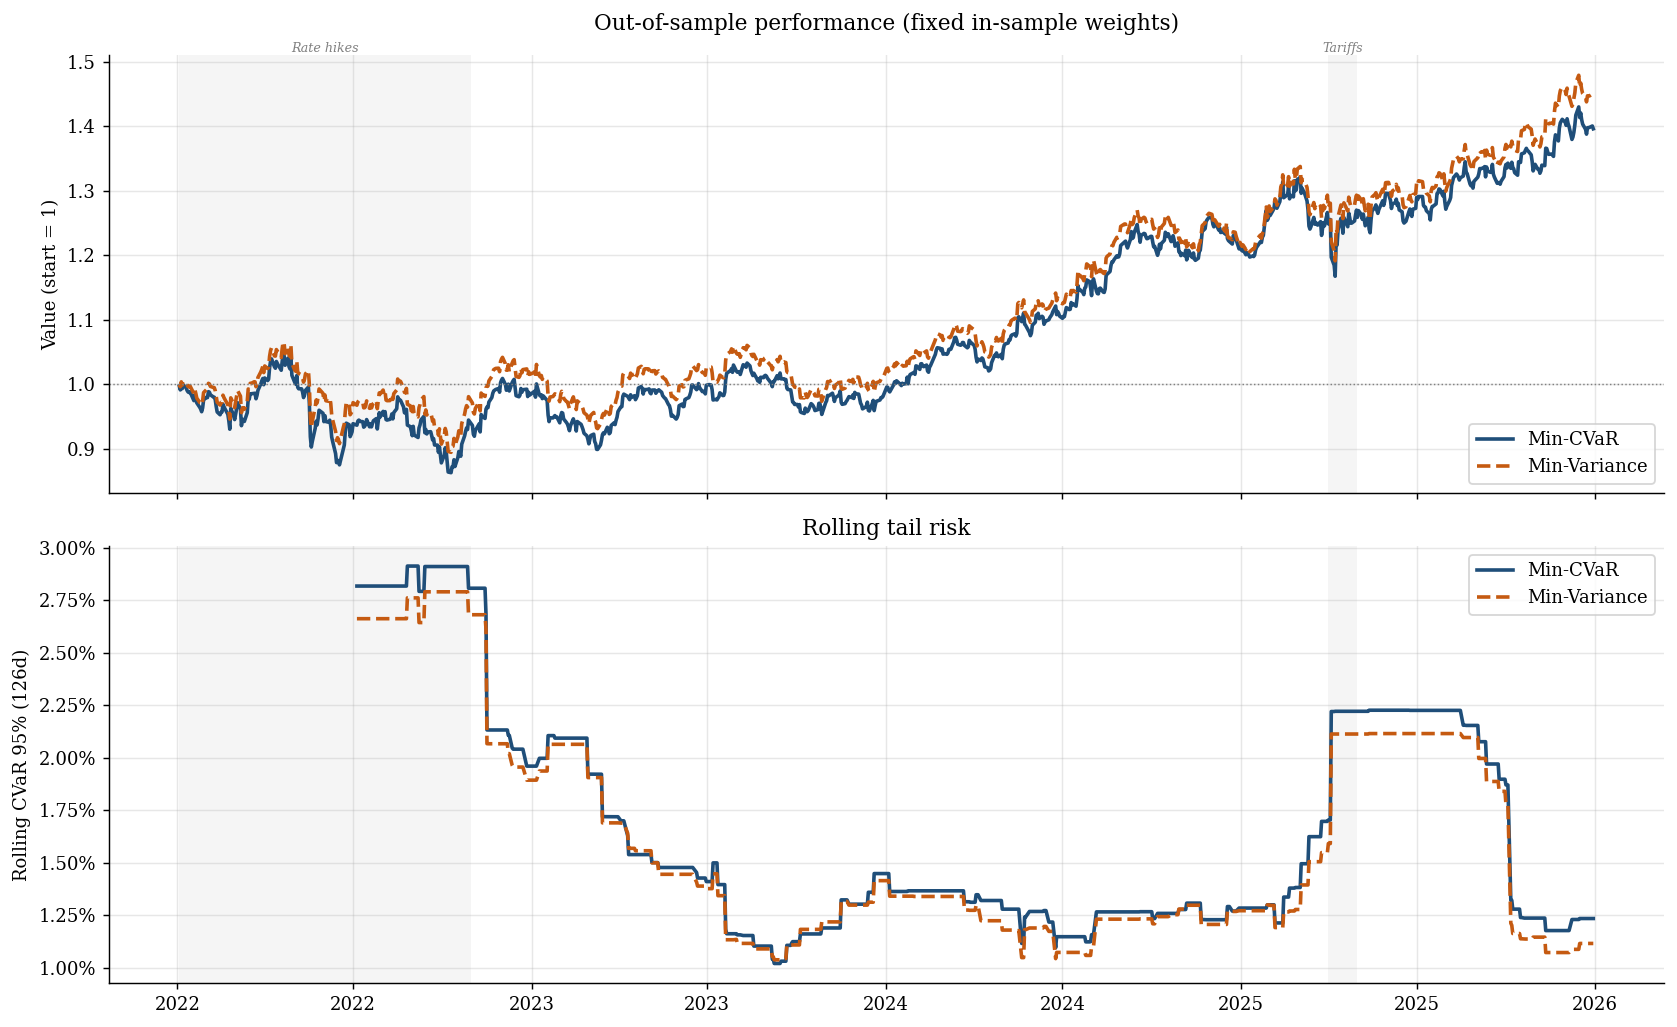

OOS CVaR(Min-CVaR) - CVaR(Min-Var), block bootstrap 95% CI: {'diff': 0.0007399874284536, 'ci_low': 0.000404470356977803, 'ci_high': 0.0010941584910488923, 'p_diff_le_0': 0.0}


In [44]:
oos = out_of_sample_evaluation(results, data.test_returns, alpha=ALPHA)
display(oos.T)
fig = plots.plot_oos_performance(results, data.test_returns, data.test_dates, alpha=ALPHA,
                                 window=126, save_path="results/oos_performance.png"); plt.show()

ci = cvar_difference_ci(data.test_returns @ cvar_result.weights,
                        data.test_returns @ mv_result.weights, alpha=ALPHA)
print("OOS CVaR(Min-CVaR) - CVaR(Min-Var), block bootstrap 95% CI:", ci)

**Interpretation.** In earlier runs Min-CVaR did *not* beat Min-Variance out of sample, not even on CVaR, the very criterion it optimises. This is not a bug but a well-known effect of *estimation error*:

- At $\alpha = 0.95$ the CVaR estimate rests on only $\approx 150$ tail days, while the covariance matrix uses all $\approx 3000$ observations.
- The tail days are dominated by one episode (March 2020). Min-CVaR therefore partly optimises against *that specific* crash.

The bootstrap confidence interval shows whether the out-of-sample difference can be distinguished from noise at all. The next section quantifies the estimation error directly.

## Step 7: Robustness

### 7a. Bootstrap Stability of the Weights

,std of weight (Min-CVaR),std of weight (Min-Variance)
AAPL,0.0139642,0.0127458
AMZN,0.0234669,0.0162494
BAC,4.92162e-13,9.43807e-06
CVX,7.37724e-12,0.000107185
GOOGL,0.014192,0.00754865
GS,2.41285e-12,0.0017658
JNJ,0.057832,0.0346661
JPM,1.46585e-12,8.59771e-05
KO,0.0399828,0.0251111
MSFT,3.04678e-11,0.000143954


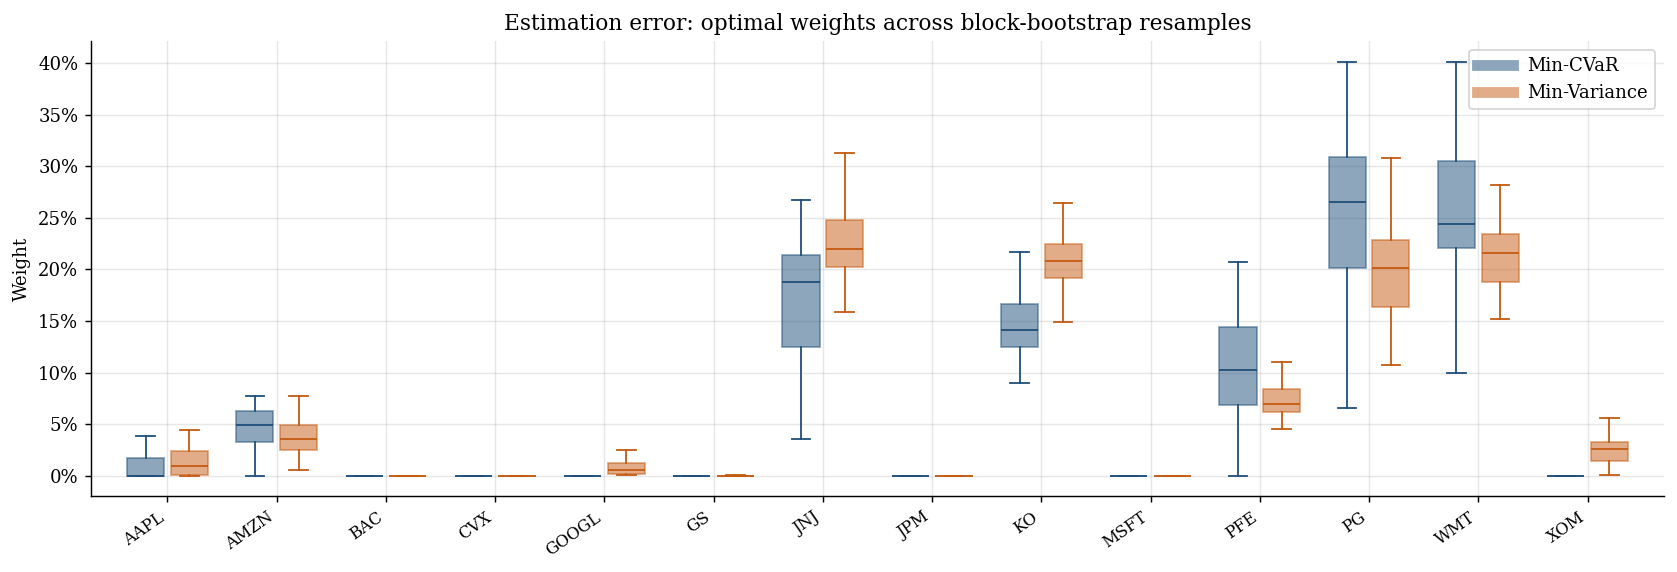

In [45]:
boot = {
    "Min-CVaR": bootstrap_weights(data.train_returns, lambda R: optimize_min_cvar(R, ALPHA),
                                  data.tickers, n_boot=50, block=20),
    "Min-Variance": bootstrap_weights(data.train_returns, lambda R: optimize_mean_variance(R, ALPHA),
                                      data.tickers, n_boot=50, block=20),
}
display(pd.DataFrame({k: v.clip(lower=0).std() for k, v in boot.items()}).rename(
    columns=lambda c: f"std of weight ({c})"))
fig = plots.plot_bootstrap_weights(boot, save_path="results/bootstrap_weights.png"); plt.show()

### 7b. Sensitivity to the Confidence Level $\alpha$

,AAPL,AMZN,BAC,CVX,GOOGL,GS,JNJ,JPM,KO,MSFT,PFE,PG,WMT,XOM,cvar,var
alpha,,,,,,,,,,,,,,,,
0.8,0.0292222,0.0140695,2.31081e-13,2.27532e-12,7.60666e-12,1.34659e-12,0.197082,5.8452e-13,0.161689,1.97935e-12,0.113537,0.249129,0.21062,0.024653,0.0104012,0.00443796
0.85,0.0331077,0.0104847,6.36731e-13,4.34984e-12,1.54601e-11,2.32265e-12,0.18913,1.03858e-12,0.176039,4.06929e-12,0.126499,0.259373,0.199234,0.00613246,0.0121631,0.00585679
0.9,0.0181407,0.0265638,1.17984e-12,2.72911e-11,9.95852e-11,7.42039e-12,0.181044,4.3083e-12,0.159459,1.82845e-11,0.129631,0.252813,0.22785,0.00449837,0.0147672,0.00822966
0.925,0.0071465,0.034584,5.08825e-14,1.21128e-12,2.2813e-11,3.38415e-13,0.209372,2.75017e-13,0.144251,1.06589e-12,0.11984,0.245842,0.238964,7.74701e-12,0.0166958,0.00981041
0.95,7.0857e-12,0.0491284,-8.66925e-15,2.39969e-12,6.97031e-12,6.08449e-13,0.203544,4.54051e-13,0.135434,2.00225e-12,0.08463,0.270947,0.256316,5.91095e-12,0.0196219,0.0121511
0.975,1.45875e-11,0.0761622,4.52935e-13,1.19063e-11,6.3888e-11,4.24149e-12,0.195214,3.55536e-12,0.185871,1.16542e-11,0.0557708,0.180942,0.306041,1.98733e-11,0.0254079,0.0159366
0.99,4.29654e-11,0.138183,3.97066e-12,5.73788e-11,8.69283e-11,1.66767e-11,0.152962,1.67458e-11,0.102501,3.02362e-11,2.39425e-10,0.288598,0.317757,3.64056e-11,0.0348279,0.0245078


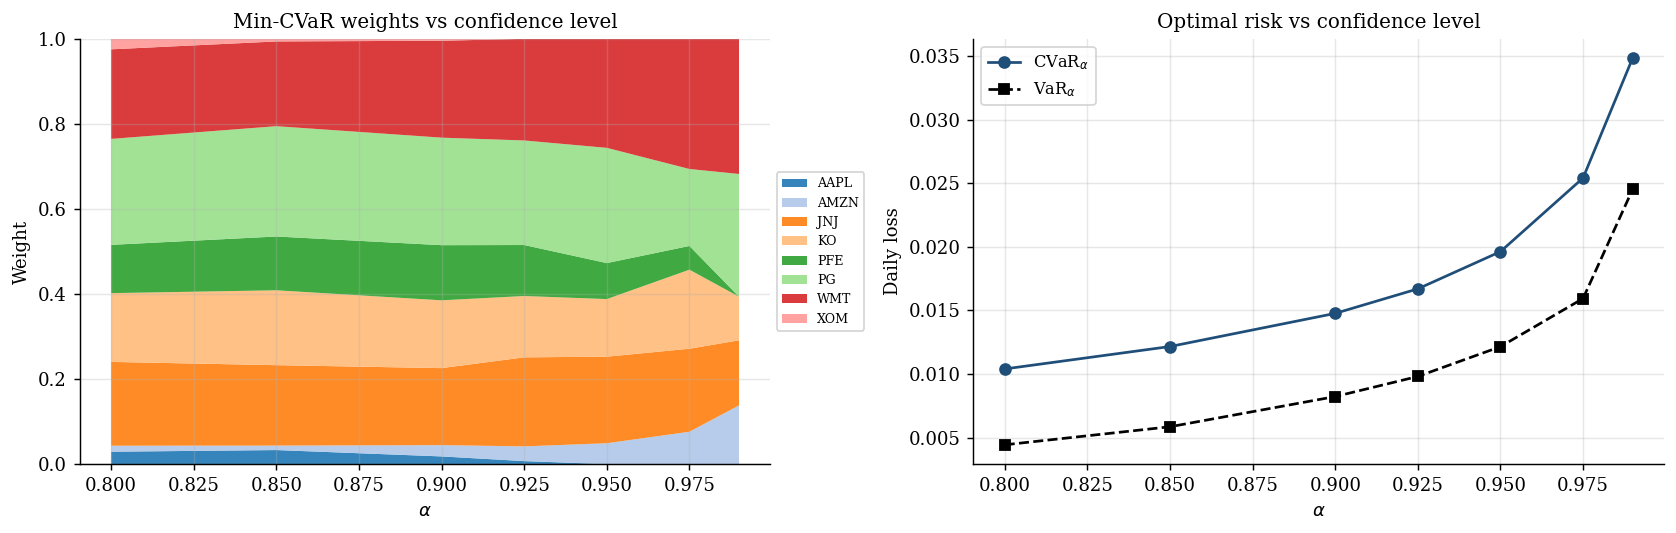

In [46]:
alphas = [0.80, 0.85, 0.90, 0.925, 0.95, 0.975, 0.99]
sens = alpha_sensitivity(data.train_returns, alphas, data.tickers, optimize_min_cvar)
display(sens)
fig = plots.plot_alpha_sensitivity(sens, data.tickers, save_path="results/alpha_sensitivity.png"); plt.show()

### 7c. Walk-Forward Backtest

A single train/test split is one draw. Here the portfolio is re-optimised every quarter on the trailing three years, using only past data at each step.

,Min-CVaR,Min-Variance
ann. return,0.115912,0.110202
ann. vol,0.14446,0.141368
CVaR (daily),0.021246,0.020799
turnover / rebal.,0.287742,0.14173


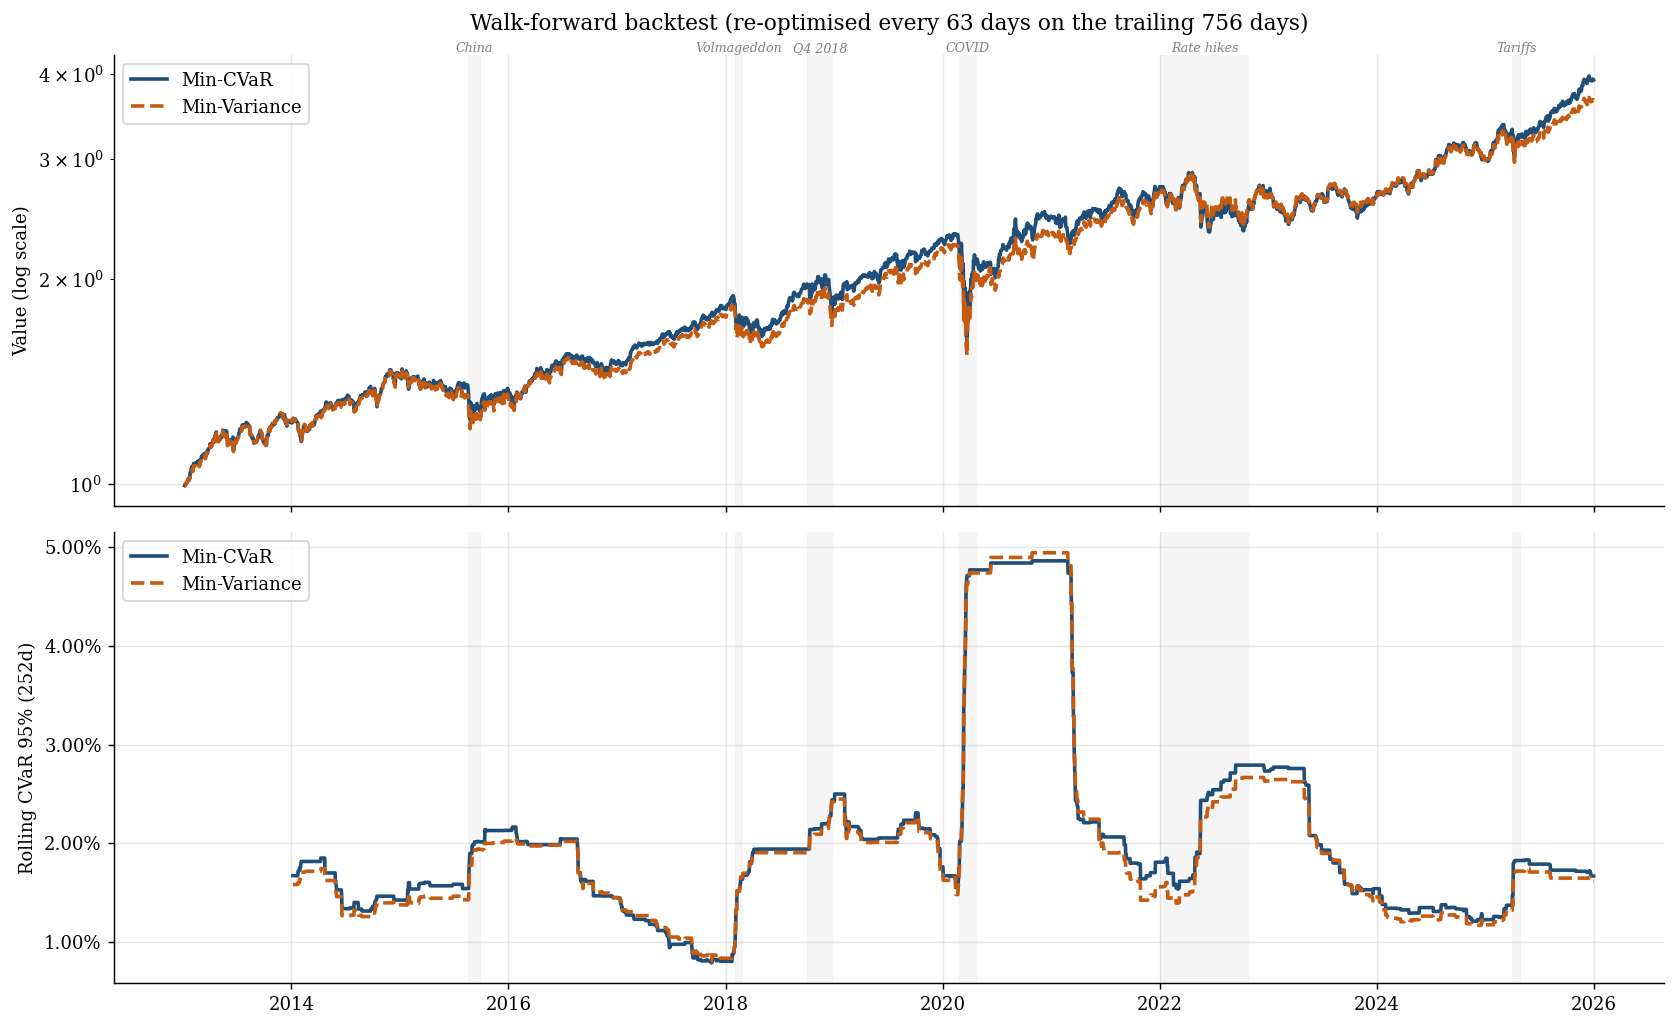

In [47]:
all_returns = data.returns.to_numpy()
port, hist = rolling_backtest(
    all_returns, data.returns.index,
    {"Min-CVaR": lambda R: optimize_min_cvar(R, ALPHA),
     "Min-Variance": lambda R: optimize_mean_variance(R, ALPHA)},
    lookback=756, rebalance=63,
)
bt = pd.DataFrame({name: {"ann. return": r.mean() * 252,
                          "ann. vol": r.std() * np.sqrt(252),
                          "CVaR (daily)": empirical_cvar(-r.to_numpy(), ALPHA),
                          "turnover / rebal.": hist[name].diff().abs().sum(axis=1).iloc[1:].mean()}
                   for name, r in port.items()})
display(bt)
fig = plots.plot_backtest(port, alpha=ALPHA, lookback=756, rebalance=63, save_path="results/backtest.png"); plt.show()

## Conclusion

- The CVaR-LP is solved to machine precision. The dual $q^*$ lies in the risk envelope $\mathcal Q$, strong duality holds, and the KKT conditions can be verified asset by asset.
- $q^*$ is the worst-case reweighting of history. Its non-uniqueness (fractional atoms on scenarios tied at $\eta^*$) is generic for the *optimised* portfolio and not a numerical artefact.
- Out of sample, the theoretical advantage of CVaR is offset by the much larger estimation error of tail quantities.